# 07 — Weather-based availability and the new "actual" prices

**Does:** turns daily weather into daily availability factors for solar, wind and hydro in every state, re-runs the Part 1 dispatch with them for all 1,917 days, and compares the result with the constant (Step 8b) and seasonal (Step 10) runs. This run is the **"actual" price** that Part 2's forecasts are scored against.

**Question:** what changes when renewable supply follows the real weather day by day instead of a fixed monthly pattern?

**Input:** `data/processed/weather_state_daily.csv` (notebook 06), hourly 100 m wind for the 17 wind points (downloaded here, cached in `data/cache/wind_hourly/`), Part 1 inputs

**Output:** `data/processed/availability_daily.csv`; `data/processed/dispatch_weather_{state,flows,national}_daily.csv`

**Code:** `src/availability.py` (tested in `tests/test_availability.py`); `src/dispatch.py` now accepts a factor per state and fuel

**Logged in:** `docs/model_log.md`, Step 15

## Design (Stage 2 decisions)

Each fuel gets a **physical rule** that gives a daily *index* (the shape). The index is then **scaled so each state's 2020–2024 average equals the Part 1 factor** (the level), and capped at 1.0. So every state's yearly renewable supply is the same as in Part 1; only the *timing* comes from the weather.

| Fuel | Rule | Assumptions |
|---|---|---|
| Solar | radiation × (1 − 0.004 × (panel temp − 25 °C)) | Panel temp = air max + 25 °C × (sunlight / 800 W/m²); daily radiation spread over 10 sunlit hours |
| Wind | Power curve on **each hour's** 100 m wind, averaged over the day, then over the state's points | 0 below 3 m/s, rising with speed³, full output 12–25 m/s, 0 above 25 m/s |
| Large hydro | Leaky bucket of water, half-life **60 days** | Big reservoirs release over months |
| Small hydro | Leaky bucket, half-life **10 days** | Mostly run-of-river |
| Hydro, 5 Himalayan states | Water = rain + **snowmelt**; melt ∝ max(dam mean temp − 15 °C, 0) | Melt = 50% of the yearly water (HP, Uttarakhand, J&K, Sikkim, Arunachal) |
| Level | Each **state's** mean over 2020–2024 = Part 1 factor (solar 0.25, wind 0.30, large hydro 0.45, small hydro 0.40), max 1.0 | Coal and all other fuels unchanged |

In [1]:
import sys
sys.path.append("../src")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import weather as w
import availability as av
from dispatch import (AVAILABILITY, LossDispatchModel, daily_availability_lookup, load_coordinates,
                      load_demand, load_generators, load_seasonal_availability, loss_matrix, run_all_days, PROCESSED)
from forecast import TEST_START, persistence, score

points = w.load_points()
state_weather = pd.read_csv(w.PROCESSED / "weather_state_daily.csv", parse_dates=["Date"])
gen = load_generators()
FULL = slice("2020-01-01", "2024-12-31")

## 1. Wind: why hourly

A power curve bends, so the output of the *average* wind is not the *average* output. Hourly wind for the 17 wind points is downloaded once (cached) and the curve is applied hour by hour.

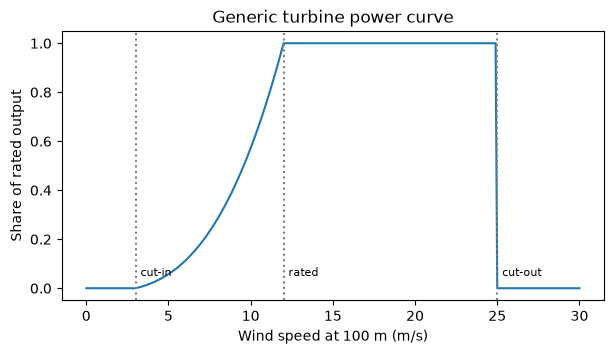

In [2]:
v = np.linspace(0, 30, 301)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(v, av.wind_power_curve(v))
for x, label in [(av.CUT_IN_MS, "cut-in"), (av.RATED_MS, "rated"), (av.CUT_OUT_MS, "cut-out")]:
    ax.axvline(x, color="grey", ls=":"); ax.text(x + 0.3, 0.05, label, fontsize=8)
ax.set_xlabel("Wind speed at 100 m (m/s)"); ax.set_ylabel("Share of rated output")
ax.set_title("Generic turbine power curve")
plt.show()

In [3]:
hourly = w.fetch_all_hourly(points[points.Purpose == "wind"], verbose=False)
assert hourly.groupby("Point_ID").size().eq(1948 * 24).all() and hourly.notna().all().all()

speed = hourly["wind_speed_100m"] / 3.6
daily_mean_speed = speed.groupby([hourly.Point_ID, hourly.Time.dt.normalize()]).mean()
print(f"average output, curve applied each hour:       {av.wind_power_curve(speed).mean():.3f}")
print(f"average output, curve applied to the daily mean: {av.wind_power_curve(daily_mean_speed).mean():.3f}")

wind_output = av.daily_wind_output(hourly, points)

average output, curve applied each hour:       0.151
average output, curve applied to the daily mean: 0.133


Hourly gives ~13% more output on average than the daily-mean shortcut. That is smaller than the 2× of the extreme example (2 and 10 m/s), because most days' winds vary less than that; but the shortcut also pushes calm days to zero, which distorts the day-to-day pattern we care about.

## 2. Solar: heat loss on hot days

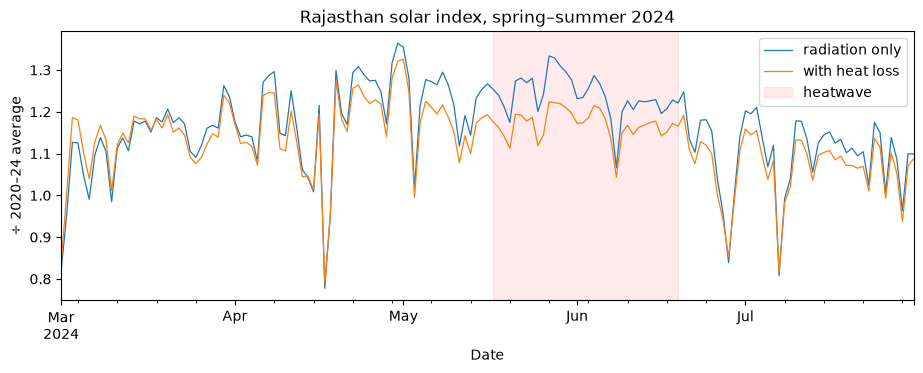

heat loss, heatwave days (20 May – 5 Jun 2024): 16.3%
heat loss, January 2024:                       3.7%


In [4]:
rj = state_weather.query("State == 'Rajasthan' and Purpose == 'solar'").set_index("Date")
with_loss = pd.Series(av.solar_index(rj.shortwave_radiation_sum, rj.temperature_2m_max), index=rj.index)
no_loss = rj.shortwave_radiation_sum
loss_pct = (1 - with_loss / no_loss) * 100

fig, ax = plt.subplots(figsize=(11, 3.5))
window = slice("2024-03-01", "2024-07-31")
(no_loss.loc[window] / no_loss.loc[FULL].mean()).plot(ax=ax, lw=0.9, label="radiation only")
(with_loss.loc[window] / with_loss.loc[FULL].mean()).plot(ax=ax, lw=0.9, label="with heat loss")
ax.axvspan("2024-05-17", "2024-06-19", color="red", alpha=0.08, label="heatwave")
ax.set_ylabel("÷ 2020–24 average"); ax.legend()
ax.set_title("Rajasthan solar index, spring–summer 2024")
plt.show()

print(f"heat loss, heatwave days (20 May – 5 Jun 2024): {loss_pct.loc['2024-05-20':'2024-06-05'].mean():.1f}%")
print(f"heat loss, January 2024:                       {loss_pct.loc['2024-01'].mean():.1f}%")

## 3. Hydro: rain + snowmelt → leaky buckets

HP, the largest hydro state, as the example. The bucket "remembers" water: the fast one (small hydro) follows rain within days, the slow one (large hydro) fills in the monsoon and drains through the autumn.

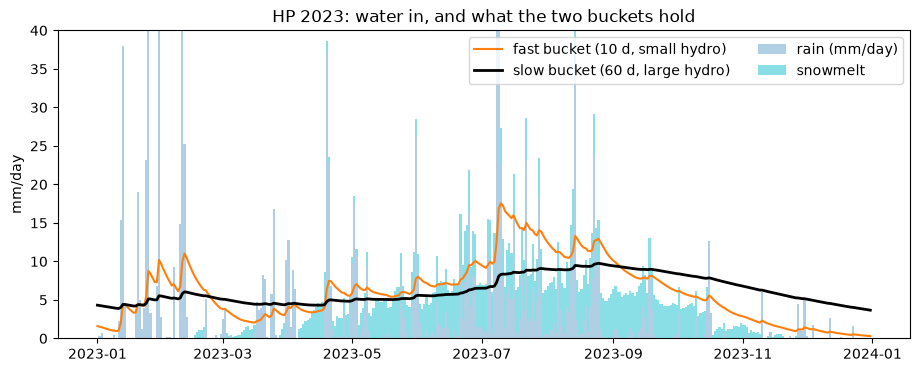

HP melt share of water 2020–24: 50%
melt by month (mm/day): {1: 0.0, 2: 0.1, 3: 0.9, 4: 2.8, 5: 4.9, 6: 6.3, 7: 5.9, 8: 5.6, 9: 5.0, 10: 2.9, 11: 0.5, 12: 0.0}


In [5]:
hp = state_weather.query("State == 'HP' and Purpose == 'hydro'").set_index("Date")
rain = hp.precipitation_sum
melt = av.snowmelt(hp.temperature_2m_mean, rain)
inflow = rain + melt
fast = av.leaky_bucket(inflow, av.HALF_LIFE_DAYS["Small Hydro"])
slow = av.leaky_bucket(inflow, av.HALF_LIFE_DAYS["Large Hydro"])

fig, ax = plt.subplots(figsize=(11, 4))
yr = slice("2023-01-01", "2023-12-31")
ax.bar(rain.loc[yr].index, rain.loc[yr], width=1, color="tab:blue", alpha=0.35, label="rain (mm/day)")
ax.bar(melt.loc[yr].index, melt.loc[yr], width=1, bottom=rain.loc[yr], color="tab:cyan", alpha=0.5, label="snowmelt")
ax.plot(fast.loc[yr], color="tab:orange", lw=1.5, label="fast bucket (10 d, small hydro)")
ax.plot(slow.loc[yr], color="black", lw=2, label="slow bucket (60 d, large hydro)")
ax.set_ylim(0, 40); ax.set_ylabel("mm/day"); ax.legend(ncol=2)
ax.set_title("HP 2023: water in, and what the two buckets hold")
plt.show()

print(f"HP melt share of water 2020–24: {melt.loc[FULL].sum() / inflow.loc[FULL].sum():.0%}")
print("melt by month (mm/day):", melt.loc[FULL].groupby(melt.loc[FULL].index.month).mean().round(1).to_dict())

## 4. All states: build and check

In [6]:
avail = av.build_availability(state_weather, wind_output, gen)

cap = gen.groupby(["State", "Fuel_Type"])["Capacity_MW"].sum()
needed = {k for k in cap[cap > 0].index if k[1] in av.WEATHER_FUELS}
built = set(zip(avail.State, avail.Fuel_Type))
assert built == needed, "a state-fuel with capacity has no factor (or vice versa)"
assert avail.Factor.notna().all() and avail.Factor.between(0, 1).all()

state_means = avail[avail.Date.between(av.MATCH_START, av.MATCH_END)].groupby(["State", "Fuel_Type"]).Factor.mean()
for (state, fuel), m in state_means.items():
    assert abs(m - AVAILABILITY[fuel]) < 1e-6, (state, fuel, m)

print(f"{len(needed)} state-fuel pairs x {avail.Date.nunique()} days = {len(avail):,} rows")
avail.groupby("Fuel_Type").Factor.agg(["min", "mean", "max", lambda s: (s >= 0.9999).mean()]).rename(
    columns={"<lambda_0>": "share of days at cap"}).round(3)

93 state-fuel pairs x 1948 days = 181,164 rows


,min,mean,max,share of days at cap
Fuel_Type,,,,
Large Hydro,0.049,0.443,1.000,0.030
Small Hydro,0.000,0.382,1.000,0.140
Solar,0.014,0.249,0.434,0.000
Wind,0.000,0.294,1.000,0.051


### Monthly shape vs Step 10

Capacity-weighted India average by month (2020–2024) against the assumed monthly factors.

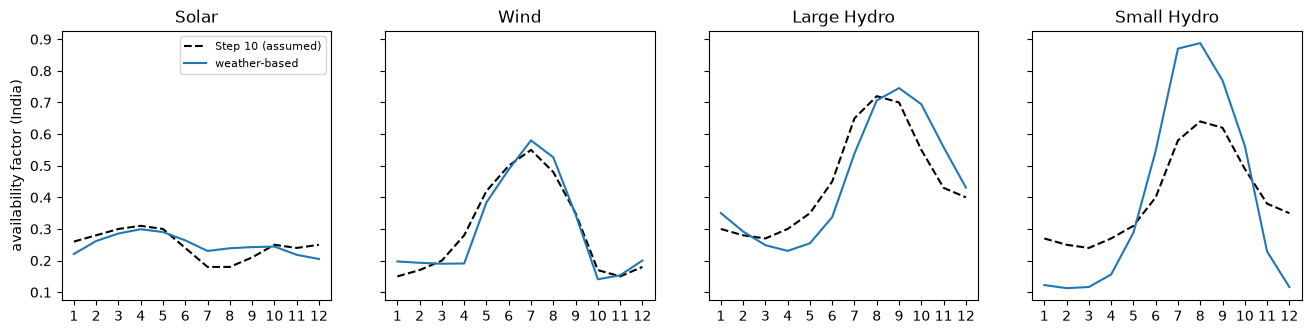

weather                         Step 10                    \
      Large Hydro Small Hydro Solar  Wind   Solar  Wind Large Hydro   
Month                                                                 
1            0.35        0.12  0.22  0.20    0.26  0.15        0.30   
2            0.29        0.11  0.26  0.19    0.28  0.17        0.28   
3            0.25        0.12  0.29  0.19    0.30  0.20        0.27   
4            0.23        0.16  0.30  0.19    0.31  0.28        0.30   
5            0.25        0.29  0.29  0.38    0.30  0.42        0.35   
6            0.34        0.55  0.26  0.49    0.24  0.50        0.45   
7            0.54        0.87  0.23  0.58    0.18  0.55        0.65   
8            0.71        0.89  0.24  0.53    0.18  0.48        0.72   
9            0.75        0.77  0.24  0.35    0.21  0.35        0.70   
10           0.69        0.56  0.24  0.14    0.25  0.17        0.55   
11           0.56        0.23  0.22  0.15    0.24  0.15        0.43   
12           0.43        0.12  0.20  0.20    0.25  0.18        0.40   

                   
      Small Hydro  
Month              
1            0.27  
2            0.25  
3            0.24  
4            0.27  
5            0.31  
6            0.40  
7            0.58  
8            0.64  
9            0.62  
10           0.49  
11           0.38  
12           0.35

In [7]:
seasonal = load_seasonal_availability()
a = avail[avail.Date.between(av.MATCH_START, av.MATCH_END)].join(cap.rename("Cap"), on=["State", "Fuel_Type"])
a["Month"] = a.Date.dt.month
national = (a.assign(x=a.Factor * a.Cap).groupby(["Fuel_Type", "Month"]).x.sum()
            / a.groupby(["Fuel_Type", "Month"]).Cap.sum()).unstack(0)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, fuel in zip(axes, av.WEATHER_FUELS):
    ax.plot(seasonal.index, seasonal[fuel], "k--", label="Step 10 (assumed)")
    ax.plot(national.index, national[fuel], label="weather-based")
    ax.set_title(fuel); ax.set_xticks(range(1, 13))
axes[0].set_ylabel("availability factor (India)"); axes[0].legend(fontsize=8)
plt.show()
pd.concat({"weather": national, "Step 10": seasonal}, axis=1).round(2)

In [8]:
avail.to_csv(PROCESSED / "availability_daily.csv", index=False, float_format="%.4f")
print(f"saved {len(avail):,} rows")

saved 181,164 rows


## 5. Dispatch with weather-based availability

Same model as notebooks 03 and 04 (loss model, coal tiers), but each day gets its own factor for every state's solar, wind and hydro. Coal and all other fuels keep their constant factors.

In [9]:
demand = load_demand()
states = list(demand.columns)
model = LossDispatchModel(gen, loss_matrix(load_coordinates(), states), states)
lookup = daily_availability_lookup(avail[avail.Date >= demand.index.min()])

t = time.time()
state_daily, flows_daily, national_daily = run_all_days(model, demand, daily=lookup)
print(f"{len(national_daily)} days in {time.time() - t:.1f} s")

nat = national_daily.set_index("Date")
assert (nat.Unserved_MW == 0).all()
assert np.allclose(nat.Demand_MW, demand.sum(axis=1))
gen_cols = [c for c in nat.columns if c.endswith("_MW") and c not in ("Demand_MW", "Unserved_MW", "Traded_MW", "Losses_MW")]
assert np.allclose(nat[gen_cols].sum(axis=1), nat.Demand_MW + nat.Losses_MW)   # energy balance every day
print(f"losses: {nat.Losses_MW.sum() / nat.Traded_MW.sum():.2%} of traded power")

# named dispatch_weather_* so they can't overwrite weather_state_daily.csv (the weather itself)
for name, df in [("state", state_daily), ("flows", flows_daily), ("national", national_daily)]:
    df.to_csv(PROCESSED / f"dispatch_weather_{name}_daily.csv", index=False)

1917 days in 10.1 s
losses: 3.77% of traded power


## 6. Compare with the constant and seasonal runs

In [10]:
runs = {"constant (8b)": pd.read_csv(PROCESSED / "dispatch_national_daily.csv", parse_dates=["Date"]).set_index("Date"),
        "seasonal (10)": pd.read_csv(PROCESSED / "seasonal_national_daily.csv", parse_dates=["Date"]).set_index("Date"),
        "weather (15)": nat}
summary = pd.DataFrame({name: {"mean price 2020–24": d.Price_avg.loc[FULL].mean(),
                               "price std": d.Price_avg.std(),
                               "mean day-to-day change": d.Price_avg.diff().abs().mean(),
                               "system cost (M Rs/h)": d.Total_cost_Rs_per_h.loc[FULL].mean() / 1e6}
                        for name, d in runs.items()}).T
summary.round(1)

,mean price 2020–24,price std,mean day-to-day change,system cost (M Rs/h)
constant (8b),2652.9,323.9,58.8,251.0
seasonal (10),2657.9,356.1,52.8,251.3
weather (15),2667.4,422.1,73.9,252.7


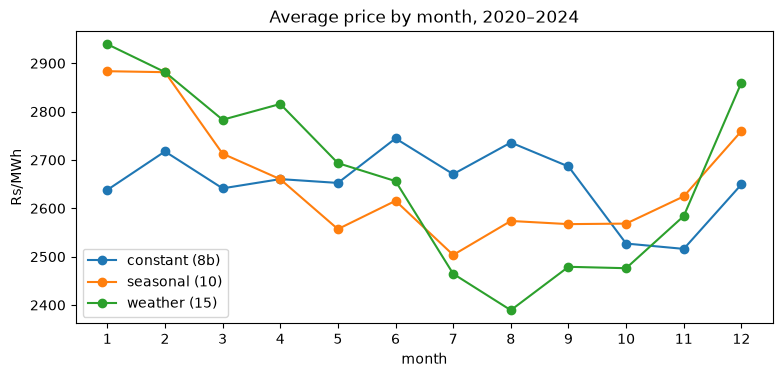

,constant (8b),seasonal (10),weather (15),weather − seasonal
Date,,,,
1,2638.0,2883.0,2939.0,56.0
2,2718.0,2881.0,2882.0,0.0
3,2641.0,2713.0,2783.0,70.0
4,2660.0,2660.0,2816.0,156.0
5,2652.0,2557.0,2693.0,136.0
6,2745.0,2616.0,2656.0,41.0
7,2671.0,2503.0,2465.0,-39.0
8,2736.0,2574.0,2389.0,-185.0
9,2686.0,2567.0,2479.0,-88.0


In [11]:
monthly = pd.DataFrame({name: d.Price_avg.loc[FULL].groupby(d.loc[FULL].index.month).mean() for name, d in runs.items()})
fig, ax = plt.subplots(figsize=(9, 3.8))
monthly.plot(ax=ax, marker="o")
ax.set_xticks(range(1, 13)); ax.set_xlabel("month"); ax.set_ylabel("Rs/MWh")
ax.set_title("Average price by month, 2020–2024")
plt.show()
monthly.assign(**{"weather − seasonal": monthly["weather (15)"] - monthly["seasonal (10)"]}).round(0)

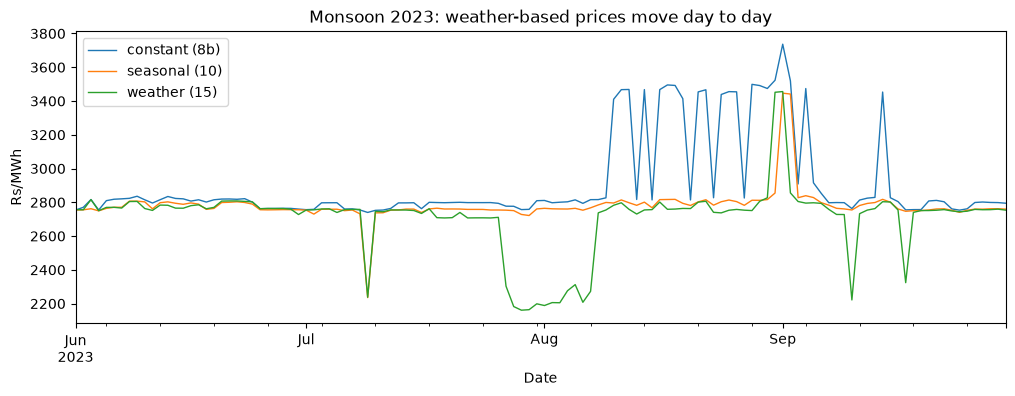

In [12]:
fig, ax = plt.subplots(figsize=(12, 3.8))
window = slice("2023-06-01", "2023-09-30")
for name, d in runs.items():
    d.Price_avg.loc[window].plot(ax=ax, lw=1, label=name)
ax.set_ylabel("Rs/MWh"); ax.legend()
ax.set_title("Monsoon 2023: weather-based prices move day to day")
plt.show()

In [13]:
mix = {}
s = runs["seasonal (10)"].loc[FULL]
for fuel in ["Coal", "Solar", "Wind", "Large Hydro", "Small Hydro"]:
    diff = nat.loc[FULL, f"{fuel}_MW"] - s[f"{fuel}_MW"]
    mix[fuel] = diff.groupby(diff.index.month).mean() / 1000
pd.DataFrame(mix).round(1).rename_axis("month").add_suffix(" (GW, weather − seasonal)")

,"Coal (GW, weather − seasonal)","Solar (GW, weather − seasonal)","Wind (GW, weather − seasonal)","Large Hydro (GW, weather − seasonal)","Small Hydro (GW, weather − seasonal)"
month,,,,,
1,0.7,-6.4,2.8,2.6,-0.8
2,1.1,-3.0,1.3,0.6,-0.7
3,4.3,-2.4,-0.6,-1.1,-0.6
4,9.8,-1.8,-5.2,-3.6,-0.6
5,7.1,-1.6,-2.1,-4.9,-0.1
6,1.2,3.9,-0.7,-5.8,0.8
7,-5.3,8.3,1.8,-5.8,1.5
8,-11.7,9.7,2.7,-0.7,1.3
9,-7.8,5.4,-0.3,2.4,0.8


## 7. Price baselines for Part 2

Stage 0 deferred price baselines until this run existed. Same test period and metrics as notebook 05, now for the demand-weighted average price.

In [14]:
price = nat.Price_avg
test = price.loc[TEST_START:]
base_mae = score(test, persistence(price, 1).loc[test.index])["MAE"]
pd.DataFrame({name: score(test, persistence(price, lag).loc[test.index], base_mae)
              for name, lag in [("Persistence (yesterday)", 1), ("Last week", 7)]}).T.round(
    {"MAE": 1, "MAPE_%": 2, "RMSE": 1, "Skill": 3})

,MAE,MAPE_%,RMSE,Skill
Persistence (yesterday),141.9,4.58,260.6,0.000
Last week,217.1,6.92,345.7,-0.531


## Conclusions

**Availability (93 state-fuel pairs × 1,948 days):** every state's 2020–24 average equals its Part 1 factor exactly, nothing is above 1.0. The cap binds on 3% of days for large hydro, 5% for wind and 14% for small hydro (monsoon peaks); never for solar.

**What each rule does:**
- **Wind:** applying the curve hour by hour gives 13% more output than the daily-mean shortcut, and keeps calm days from collapsing to zero
- **Solar:** heat loss is ~16% on heatwave days and ~4% in January. But the heatwave had clear skies and the year's strongest sun, so solar availability **did not dip** in May 2024: it stayed about level with April. My expectation of a heatwave dip was wrong; heat loss only stops it rising
- **Hydro:** in HP the snowmelt (50% of yearly water by design) runs from March to October, peaking at ~6 mm/day in June, so HP's buckets start filling in May before the monsoon. Across India, though, large hydro is lowest in March–May (0.23–0.25 vs Step 10's 0.27–0.35) and **peaks in September (0.75), a month later than Step 10**, because big reservoirs release stored monsoon water into the autumn
- **Solar vs Step 10:** higher in the monsoon (0.23–0.24 vs 0.18) and lower in winter (0.20–0.22 vs 0.25–0.26), as notebook 06 predicted

**Prices (weather run vs seasonal run, 2020–24):**
- Average price almost unchanged (Rs 2,667 vs 2,658/MWh) and system cost +0.5%: by design, the same yearly renewable supply
- **Pre-monsoon is more expensive (Apr +156, May +136 Rs/MWh):** reservoirs are low, so 7–10 GW more coal runs
- **August–October is cheaper (−185 to −88 Rs/MWh):** full reservoirs and monsoon solar push 5–12 GW of coal off
- **Winter (Dec–Jan) +56 to +100:** weaker winter solar
- **Day-to-day volatility up ~40%:** mean daily change 74 Rs/MWh vs 53; standard deviation 422 vs 356. Prices jump between coal-tier levels (~2,200, ~2,750, ~3,450) when renewable output moves a few GW, e.g. the lows of late July 2023 and the spike at the end of the record-dry August 2023
- No unserved days; losses 3.77% of traded power

**This run is now the "actual" price for Part 2.** Price baselines on the test period (2024 – Mar 2025): persistence MAE **142 Rs/MWh, MAPE 4.58%**, last week MAPE 6.92%. Price is about twice as hard to forecast as national demand (2.26%), and RMSE is 1.8× MAE: errors come in big jumps, the coal-tier steps.

**Next (Stage 3):** demand forecasting models L0–L6.